# Diabetes Health Indicators: Exploratory Data Analysis (BRFSS 2023)

**Goal:** explore which health and lifestyle factors differ between US adults with and without prediabetes or diabetes, as a first step before building a prediction model.

**Questions this notebook answers**
1. Is the data clean and usable, and how balanced is the target?
2. What does the survey weight mean, and does it change the picture?
3. Which traits differ most between the two groups?
4. How does BMI differ?
5. How does age relate to diabetes, and does age explain the other differences?
6. Do sex, education and general health matter?
7. Which traits are most linked to the target, and are any too similar to each other?

**Data source:** the CDC's Behavioral Risk Factor Surveillance System (BRFSS), an annual health survey of US adults run by state health departments with the CDC. I used the **2023** survey year, read from the `hesscl/quackrfss` dataset on Hugging Face, which republishes the CDC files in Parquet format.

**Target variable:** `diabetes_binary` (0 = no diabetes, 1 = prediabetes or diabetes).

**Sources:**
- CDC BRFSS annual data and codebooks: https://www.cdc.gov/brfss/annual_data/annual_data.htm
- quackrfss (Parquet version of BRFSS): https://huggingface.co/datasets/hesscl/quackrfss

## Data preparation

The cleaned file `brfss2023_diabetes_clean.csv` was built in a separate notebook:

1. Loaded only the 2023 survey year and kept the columns relevant to diabetes risk.
2. Replaced survey codes for "don't know" and "refused" (7, 9, 77, 99) with missing values. In the days-of-poor-health questions, code 88 means "none" and was set to 0.
3. Converted yes/no answers to 1/0, and divided BMI by 100 because the source stores it multiplied by 100.
4. Target: "no diabetes" includes people who had diabetes **only during pregnancy**. Prediabetes and diabetes were merged into one group, because prediabetes alone was only 2.6% of the data.
5. `chol_check`: "never had a cholesterol check" and "not within the past 5 years" were both coded 0.
6. Dropped 984 people with no diabetes answer, then dropped the `income` column because 20% of answers were missing.
7. Dropped rows with any remaining missing value. This kept **300,760 of 433,323** respondents (69.4%).

Every choice and its reason is documented in `01_data_preparation.ipynb`.

**Limitations to keep in mind**
- Fruit and vegetable intake is not available in the 2023 file, so those two common indicators are missing.
- Removing incomplete rows means the remaining people may differ from those who skipped questions.

## Q1. Is the data usable, and how balanced is the target?

In [1]:
import warnings
warnings.filterwarnings("ignore")   

import pandas as pd                
import numpy as np               
import matplotlib.pyplot as plt   
import seaborn as sns              

sns.set_theme(style="whitegrid")

df = pd.read_csv("brfss2023_diabetes_clean.csv")   

print(df.shape)   
df.head()         

(300760, 20)


,high_bp,high_chol,chol_check,bmi,smoker,stroke,heart_disease,phys_activity,heavy_drinker,any_healthcare,no_doc_cost,gen_health,ment_health_days,phys_health_days,diff_walk,sex,age_group,education,weight,diabetes_binary
0,1.0,0.0,1.0,30.47,0.0,0.0,0.0,0.0,0.0,1.0,0.0,2.0,0.0,0.0,1.0,1,13.0,5.0,605.42786,1
1,1.0,1.0,1.0,28.56,0.0,0.0,0.0,1.0,0.0,1.0,0.0,2.0,0.0,0.0,0.0,1,13.0,5.0,1121.99270,0
2,1.0,1.0,1.0,22.31,1.0,0.0,0.0,1.0,0.0,1.0,1.0,4.0,2.0,6.0,1.0,1,13.0,4.0,600.96330,0
3,0.0,0.0,1.0,27.44,0.0,0.0,0.0,1.0,0.0,1.0,0.0,2.0,0.0,2.0,1.0,1,12.0,5.0,605.42786,0
4,1.0,0.0,1.0,25.85,0.0,0.0,0.0,1.0,0.0,1.0,0.0,4.0,0.0,0.0,1.0,1,12.0,5.0,281.71103,1


**Variable guide.** Most columns are flags: **1 = yes, 0 = no**.

| Column | Meaning |
|---|---|
| `diabetes_binary` | Target: told they have prediabetes or diabetes (1) or not (0) |
| `high_bp` | Told they have high blood pressure |
| `high_chol` | Told they have high cholesterol |
| `chol_check` | Had a cholesterol check in the past 5 years |
| `bmi` | Body mass index |
| `smoker` | Has smoked at least 100 cigarettes in their lifetime |
| `stroke` | Ever told they had a stroke |
| `heart_disease` | Coronary heart disease or heart attack |
| `phys_activity` | Any physical activity in the past 30 days outside work |
| `heavy_drinker` | Heavy alcohol use (more than 14 drinks a week for men, 7 for women) |
| `any_healthcare` | Has some form of health coverage |
| `no_doc_cost` | Needed a doctor but could not afford it in the past year |
| `gen_health` | Self-rated health: 1 = excellent ... 5 = poor |
| `ment_health_days` | Days of poor mental health in the past 30 (0-30) |
| `phys_health_days` | Days of poor physical health in the past 30 (0-30) |
| `diff_walk` | Serious difficulty walking or climbing stairs |
| `sex` | 0 = male, 1 = female |
| `age_group` | Age in 5-year bands: 1 = 18-24 ... 13 = 80 and over |
| `education` | 1 = none or kindergarten ... 6 = college graduate |
| `weight` | Survey weight (see Q2), **not** body weight |

*Definitions are summarized from the CDC BRFSS 2023 codebook*

In [2]:
df.info()                                                   
print(df.isna().sum().sum(), "missing values")              
print(df["diabetes_binary"].value_counts(normalize=True).round(3))   

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 300760 entries, 0 to 300759
Data columns (total 20 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   high_bp           300760 non-null  float64
 1   high_chol         300760 non-null  float64
 2   chol_check        300760 non-null  float64
 3   bmi               300760 non-null  float64
 4   smoker            300760 non-null  float64
 5   stroke            300760 non-null  float64
 6   heart_disease     300760 non-null  float64
 7   phys_activity     300760 non-null  float64
 8   heavy_drinker     300760 non-null  float64
 9   any_healthcare    300760 non-null  float64
 10  no_doc_cost       300760 non-null  float64
 11  gen_health        300760 non-null  float64
 12  ment_health_days  300760 non-null  float64
 13  phys_health_days  300760 non-null  float64
 14  diff_walk         300760 non-null  float64
 15  sex               300760 non-null  int64  
 16  age_group         30

**Finding:** the file loaded correctly: 300,760 people, 20 columns, no missing values. **17.3%** have prediabetes or diabetes and 82.7% do not. The classes are imbalanced, so accuracy alone will be misleading when we model later.

## Q2. What does the survey weight mean, and does it change the picture?

BRFSS interviews a sample of adults, not everyone. The `weight` column says how many US adults one respondent's answers stand for, so the sample can be scaled to the whole population. A value of 241 means that person stands for about 241 adults.

Below, **unweighted** means every respondent counts as one person, and **weighted** means each respondent counts as many times as their weight.

In [3]:
# Smallest, typical and largest weight
print(df["weight"].describe().round(0))

# Add up all weights: roughly how many US adults the data stands for
print("Total weight:", round(df["weight"].sum()))

# Diabetes rate: unweighted (every person counts as 1) vs weighted (using the weights)
unweighted = df["diabetes_binary"].mean()
weighted = (df["diabetes_binary"] * df["weight"]).sum() / df["weight"].sum()
print("Unweighted:", round(unweighted, 3))
print("Weighted:  ", round(weighted, 3))

count    300760.0
mean        542.0
std        1115.0
min           0.0
25%          97.0
50%         241.0
75%         559.0
max       69786.0
Name: weight, dtype: float64
Total weight: 163058858
Unweighted: 0.173
Weighted:   0.162


**Finding:**
- The median weight is 241 and the mean is 542, with a maximum of 69,786. Most people stand for a few hundred adults, and a few stand for many more.
- The weights add up to about 163 million adults. That is below the full US adult population because incomplete rows were removed.
- The share with prediabetes or diabetes is **17.3% unweighted** (the sample) and **16.2% weighted** (the population this cleaned data represents). The two are close, so unweighted patterns are a reasonable guide for exploring.
- The weighted figure is **not** an official national rate: it excludes people with missing answers and combines prediabetes with diabetes. A weighted check of the main comparison is at the end of Q3.

## Q3. Which traits differ most between the two groups?

First the yes/no traits (the number is the **% of people** with the trait), then every trait on one common scale.

In [4]:
# Yes/no columns only
flags = ["high_bp", "high_chol", "chol_check", "smoker", "stroke", "heart_disease",
         "phys_activity", "heavy_drinker", "any_healthcare", "no_doc_cost", "diff_walk"]

# % of people with each trait, split by group
flag_table = df.groupby("diabetes_binary")[flags].mean().T * 100
flag_table.columns = ["no_diabetes", "prediabetes_or_diabetes"]

# Gap in percentage points, and how many times more common the trait is
flag_table["gap_points"] = flag_table["prediabetes_or_diabetes"] - flag_table["no_diabetes"]
flag_table["ratio"] = flag_table["prediabetes_or_diabetes"] / flag_table["no_diabetes"]

flag_table.sort_values("gap_points", ascending=False).round(1)

,no_diabetes,prediabetes_or_diabetes,gap_points,ratio
high_bp,37.5,71.5,34.0,1.9
high_chol,38.0,64.0,26.0,1.7
diff_walk,12.2,32.4,20.2,2.7
heart_disease,6.9,19.3,12.4,2.8
smoker,38.0,45.5,7.4,1.2
stroke,3.4,8.8,5.4,2.6
chol_check,96.1,99.4,3.3,1.0
any_healthcare,96.1,97.3,1.2,1.0
no_doc_cost,7.0,7.9,0.9,1.1
heavy_drinker,6.7,2.9,-3.8,0.4


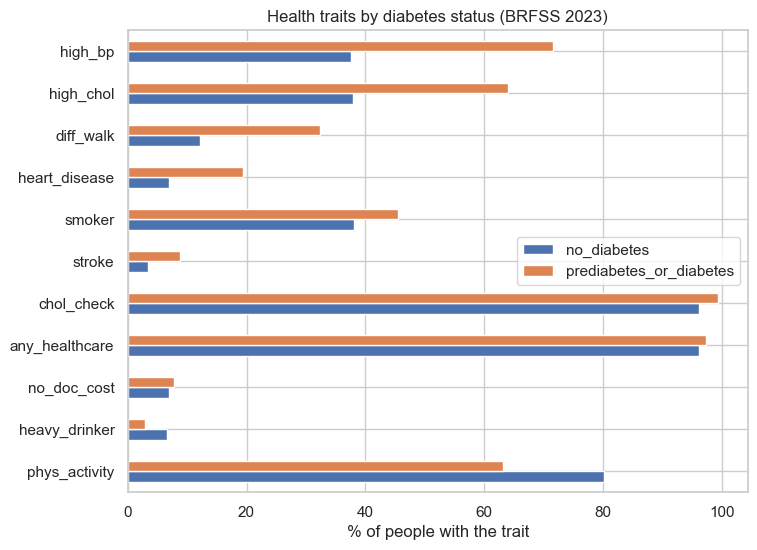

In [5]:
# Same numbers as a chart, biggest gap at the top
plot_data = flag_table.sort_values("gap_points")[["no_diabetes", "prediabetes_or_diabetes"]]

plot_data.plot(kind="barh", figsize=(8, 6))
plt.xlabel("% of people with the trait")
plt.title("Health traits by diabetes status (BRFSS 2023)")
plt.show()

**Finding:** the biggest gap in the share of people is **high blood pressure** (37.5% vs 71.5%), followed by high cholesterol (38.0% vs 64.0%) and difficulty walking (12.2% vs 32.4%). Heart disease and stroke are 2.6 to 2.8 times more common in the diabetes group, though they remain relatively uncommon. Physical activity is lower in the diabetes group (63.2% vs 80.2%). Health-care access (`any_healthcare`, `no_doc_cost`) barely differs.

,no_diabetes,prediabetes_or_diabetes,std_diff
gen_health,2.455,3.198,0.720
high_bp,0.375,0.715,0.687
diff_walk,0.122,0.324,0.555
bmi,28.097,31.639,0.546
high_chol,0.380,0.640,0.525
age_group,7.830,9.516,0.500
heart_disease,0.069,0.193,0.430
phys_health_days,3.816,7.424,0.412
stroke,0.034,0.088,0.265
chol_check,0.961,0.994,0.183


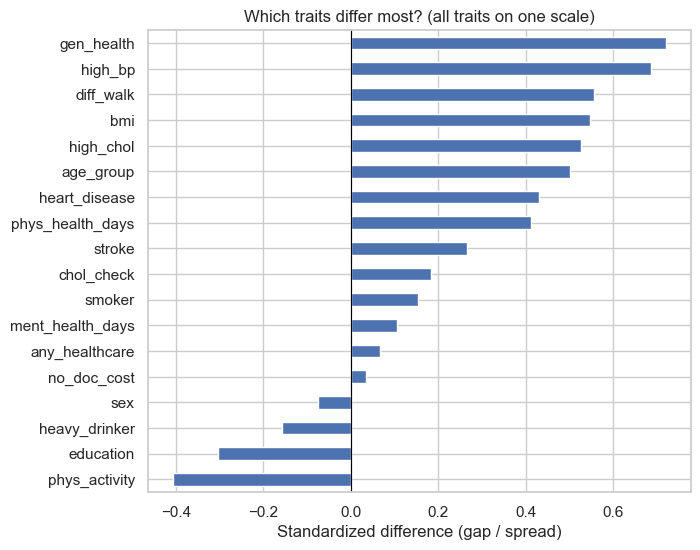

In [6]:
# Put every trait on the same scale: the gap between the groups divided by the
# spread (standard deviation) of that column. This lets us compare yes/no traits
# with scales such as BMI or age, which a simple ratio cannot do.
features = [c for c in df.columns if c not in ("diabetes_binary", "weight")]

std_table = df.groupby("diabetes_binary")[features].mean().T
std_table.columns = ["no_diabetes", "prediabetes_or_diabetes"]
std_table["std_diff"] = (std_table["prediabetes_or_diabetes"] - std_table["no_diabetes"]) / df[features].std()
std_table = std_table.sort_values("std_diff", ascending=False)

display(std_table.round(3))

# Chart: bars to the right are higher in the diabetes group, to the left lower
std_table["std_diff"].sort_values().plot(kind="barh", figsize=(7, 6))
plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("Standardized difference (gap / spread)")
plt.title("Which traits differ most? (all traits on one scale)")
plt.show()

**Finding:** on a common scale, the traits that separate the two groups most are **self-rated general health (0.72)** and **high blood pressure (0.69)**, followed by difficulty walking (0.56), BMI (0.55), high cholesterol (0.53) and age group (0.50). Heart disease (0.43) and days of poor physical health (0.41) come next. The largest gap in the other direction is **physical activity (-0.41)**, then education (-0.31) and heavy drinking (-0.16). Health-care access (`any_healthcare`, `no_doc_cost`) and sex are close to zero.

The ranking differs from the ratio table. Heart disease and stroke looked the most lopsided there (2.6 to 2.8 times more common), but they fall to 7th (0.43) and 9th (0.27) here, because they are rare traits and a ratio exaggerates the gap for rare traits. The standardized difference puts general health, blood pressure, walking difficulty, BMI, cholesterol and age at the top, the same six traits that led the correlation ranking.

In [7]:
# Each person counts as many times as the number of adults they represent.
rows = {}
for c in flags:
    no_d = df[df["diabetes_binary"] == 0]
    d = df[df["diabetes_binary"] == 1]
    rows[c] = {
        "no_diabetes_weighted_%": np.average(no_d[c], weights=no_d["weight"]) * 100,
        "diabetes_weighted_%": np.average(d[c], weights=d["weight"]) * 100,
    }

weighted_table = pd.DataFrame(rows).T
weighted_table["gap_points"] = weighted_table["diabetes_weighted_%"] - weighted_table["no_diabetes_weighted_%"]
weighted_table.sort_values("gap_points", ascending=False).round(1)

,no_diabetes_weighted_%,diabetes_weighted_%,gap_points
high_bp,32.0,68.7,36.7
high_chol,33.3,62.5,29.2
diff_walk,10.3,30.2,19.9
heart_disease,5.3,17.1,11.8
smoker,35.2,43.2,8.1
stroke,2.6,8.1,5.5
chol_check,95.6,99.2,3.6
any_healthcare,93.8,95.5,1.7
no_doc_cost,9.6,10.7,1.1
heavy_drinker,6.4,3.2,-3.2


**Finding:** weighting the respondents to the US adult population does not change the conclusions. The order of the traits is identical to the unweighted comparison (high blood pressure, high cholesterol, difficulty walking, heart disease, smoking, stroke at the top; heavy drinking and physical activity as the negative gaps), and every gap changes by less than 3.3 percentage points. The weighted gaps for high blood pressure (36.7 vs 34.0 points) and high cholesterol (29.2 vs 26.0) are slightly larger, and the others are within about one point of the unweighted ones. The weighted shares are lower in both groups for most traits (for example high blood pressure 32.0% and 68.7%), which fits a sample that leans older than the population.

## Q4. How does BMI differ?

Each group has its own chart on the same axes, so bar heights are comparable. Each chart is scaled to 100% of its group (`density`), because the groups have very different sizes.

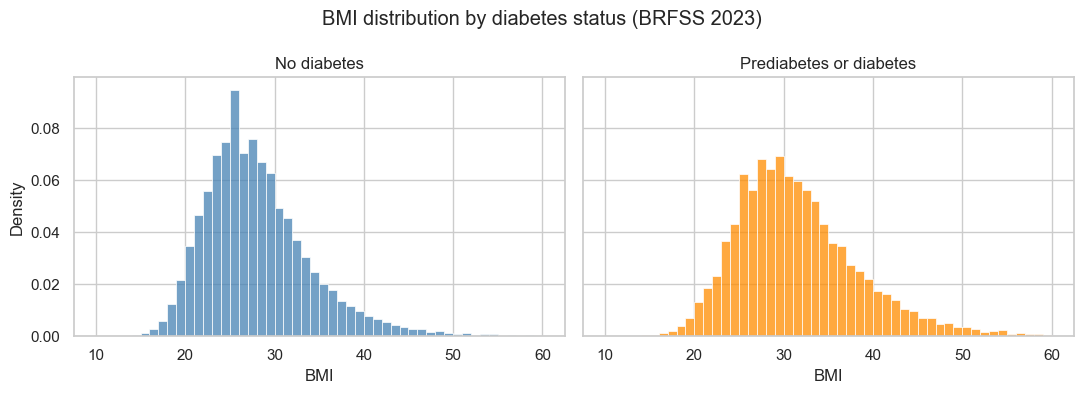

People outside the chart range: 569


In [8]:
# Two charts side by side; sharex/sharey keep the same axes so the groups are comparable
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharex=True, sharey=True)

# Left chart: people without diabetes
sns.histplot(data=df[df["diabetes_binary"] == 0], x="bmi",
             binrange=(10, 60), bins=50, stat="density",
             color="steelblue", ax=axes[0])
axes[0].set_title("No diabetes")

# Right chart: people with prediabetes or diabetes
sns.histplot(data=df[df["diabetes_binary"] == 1], x="bmi",
             binrange=(10, 60), bins=50, stat="density",
             color="darkorange", ax=axes[1])
axes[1].set_title("Prediabetes or diabetes")

for ax in axes:
    ax.set_xlabel("BMI")

plt.suptitle("BMI distribution by diabetes status (BRFSS 2023)")
plt.tight_layout()
plt.show()

# How many people have a BMI outside the 10-60 range shown in the charts?
print("People outside the chart range:", ((df["bmi"] < 10) | (df["bmi"] > 60)).sum())

In [9]:
# Exact numbers: average, median and quartiles of BMI for each group
df.groupby("diabetes_binary")["bmi"].describe().round(1)

,count,mean,std,min,25%,50%,75%,max
diabetes_binary,,,,,,,,
0,248707.0,28.1,6.1,12.0,24.0,27.1,31.0,97.2
1,52053.0,31.6,7.3,12.1,26.6,30.5,35.3,99.8


**Finding:** among people without diabetes, BMI peaks at about 25-26 and drops off quickly above 30. Among people with prediabetes or diabetes, the peak is higher (about 27-30) and the distribution is wider, with many more people between BMI 35 and 55. The average is 31.6 vs 28.1. The groups overlap heavily, so BMI alone does not separate them.

*The charts show BMI between 10 and 60; the count printed under them shows how many people fall outside that range.*

## Q5. How does age relate to diabetes, and does age explain the other differences?

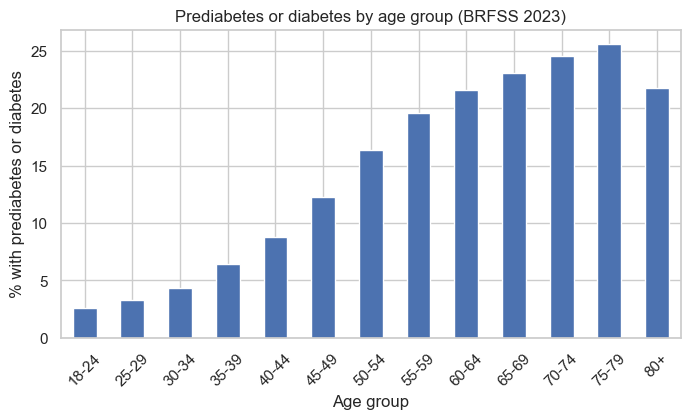

In [10]:
# Share of people in each age group with prediabetes or diabetes, as a percentage
rate_by_age = df.groupby("age_group")["diabetes_binary"].mean() * 100

# Readable labels for the 13 age bands
labels = ["18-24", "25-29", "30-34", "35-39", "40-44", "45-49", "50-54",
          "55-59", "60-64", "65-69", "70-74", "75-79", "80+"]

rate_by_age.plot(kind="bar", figsize=(8, 4))
plt.xticks(range(13), labels, rotation=45)
plt.xlabel("Age group")
plt.ylabel("% with prediabetes or diabetes")
plt.title("Prediabetes or diabetes by age group (BRFSS 2023)")
plt.show()

**Finding:** the share with prediabetes or diabetes rises from about 3% at ages 18-29 to about 25% at ages 70-79, with the steepest increase between the late 30s and mid 50s. It dips to about 22% at 80 and over; the cause cannot be determined from this data.

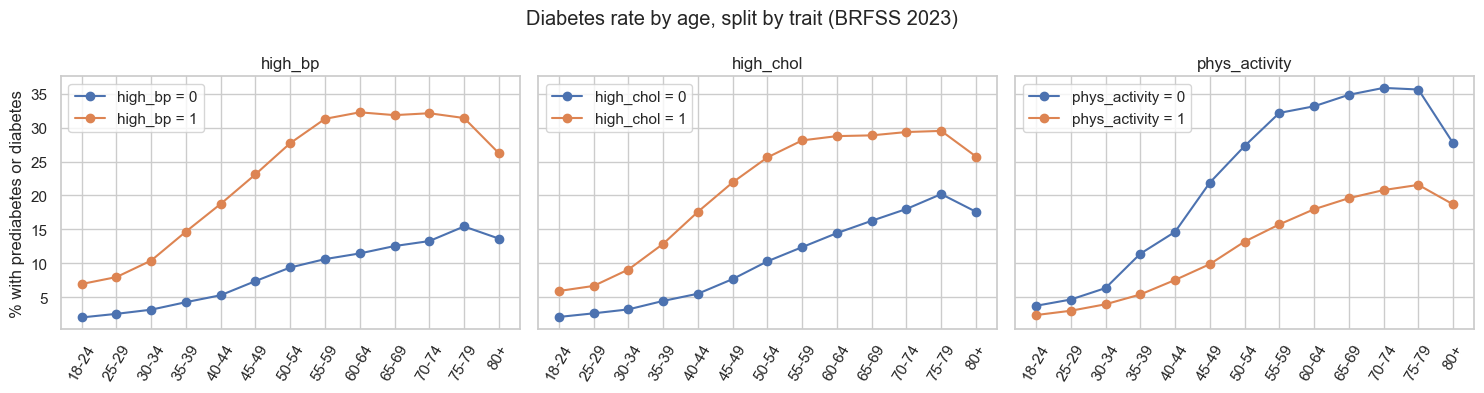

In [11]:
# Does a trait still matter at the SAME age? For each trait, draw the diabetes rate
# by age group separately for people without (0) and with (1) the trait.
traits = ["high_bp", "high_chol", "phys_activity"]
labels = ["18-24", "25-29", "30-34", "35-39", "40-44", "45-49", "50-54",
          "55-59", "60-64", "65-69", "70-74", "75-79", "80+"]

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)

for ax, t in zip(axes, traits):
    # rows = age group, columns = trait value (0/1), values = % with diabetes
    rate = df.groupby(["age_group", t])["diabetes_binary"].mean().unstack() * 100
    ax.plot(rate.index, rate[0.0], marker="o", label=f"{t} = 0")
    ax.plot(rate.index, rate[1.0], marker="o", label=f"{t} = 1")
    ax.set_xticks(range(1, 14))
    ax.set_xticklabels(labels, rotation=60)
    ax.set_title(t)
    ax.legend()

axes[0].set_ylabel("% with prediabetes or diabetes")
plt.suptitle("Diabetes rate by age, split by trait (BRFSS 2023)")
plt.tight_layout()
plt.show()

**Finding:** all three traits stay linked to prediabetes or diabetes within every age group, so the earlier gaps are not just an effect of age. The two lines never meet for high blood pressure, high cholesterol or physical activity.

- **High blood pressure:** the gap is about 5 percentage points at 18-24, peaks at about 20 points in the late 50s and early 60s, then narrows to about 13 points at 80 and over. People with high blood pressure are about 3 times as likely to be in the diabetes group through the 50s and about 2 times as likely after 75.
- **High cholesterol:** the gap follows the same shape but is smaller, about 14-15 points in the 50s and 60s and about 8-9 points after 75.
- **Physical activity:** inactive people have the higher rate. The gap is small for adults under 35 (1-3 points) and widest between 55 and 74 (about 15-16 points).
- **Age effect:** the rate rises with age within every line, so age matters in both groups, and the rate dips at 80+ in all of them.

## Q6. Do sex, education and general health matter?

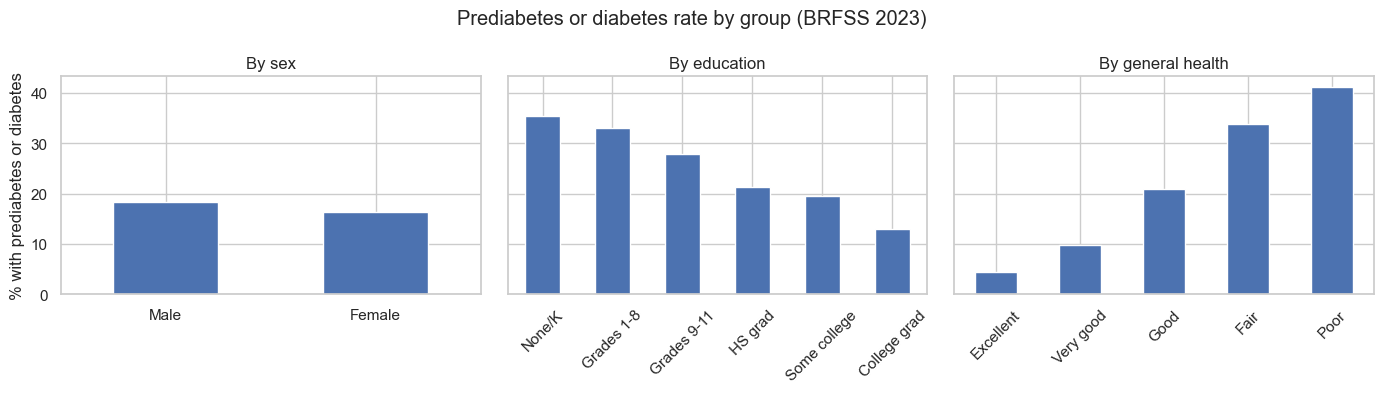

In [12]:
# Three charts in one row; sharey=True gives them the same vertical scale
fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)

# Chart 1: by sex (0 = male, 1 = female)
rate_sex = df.groupby("sex")["diabetes_binary"].mean() * 100
rate_sex.plot(kind="bar", ax=axes[0])
axes[0].set_xticklabels(["Male", "Female"], rotation=0)
axes[0].set_title("By sex")

# Chart 2: by education (1 = lowest, 6 = college graduate)
rate_edu = df.groupby("education")["diabetes_binary"].mean() * 100
rate_edu.plot(kind="bar", ax=axes[1])
axes[1].set_xticklabels(["None/K", "Grades 1-8", "Grades 9-11", "HS grad",
                         "Some college", "College grad"], rotation=45)
axes[1].set_title("By education")

# Chart 3: by self-rated general health (1 = excellent, 5 = poor)
rate_gen = df.groupby("gen_health")["diabetes_binary"].mean() * 100
rate_gen.plot(kind="bar", ax=axes[2])
axes[2].set_xticklabels(["Excellent", "Very good", "Good", "Fair", "Poor"], rotation=45)
axes[2].set_title("By general health")

for ax in axes:
    ax.set_xlabel("")
axes[0].set_ylabel("% with prediabetes or diabetes")

plt.suptitle("Prediabetes or diabetes rate by group (BRFSS 2023)")
plt.tight_layout()
plt.show()

In [13]:
# How many people are in each education group? (small groups give less precise rates)
df["education"].value_counts().sort_index()

1.0       223
2.0      3921
3.0      8796
4.0     66953
5.0     80038
6.0    140829
Name: education, dtype: int64

**Finding:**
- **Sex:** a small difference (about 18.5% of men vs 16.5% of women).
- **Education:** the rate falls steadily from about 35% (no schooling or kindergarten) to about 13% (college graduates). The lowest education groups are small, so their rates are less precise. Education is also tied to age and income, so it may reflect more than schooling.
- **General health:** the rate rises from about 4.5% (excellent) to about 41% (poor). Some of this may be a consequence of the condition rather than a cause.

## Q7. Which traits are most linked to the target, and are any too similar to each other?

Correlation runs from -1 to +1. Near +1 means two columns rise together, near -1 means one rises as the other falls, and near 0 means little **straight-line** relationship. Most columns here are yes/no or ordered scales, so treat the numbers as a rough guide rather than exact measurements.

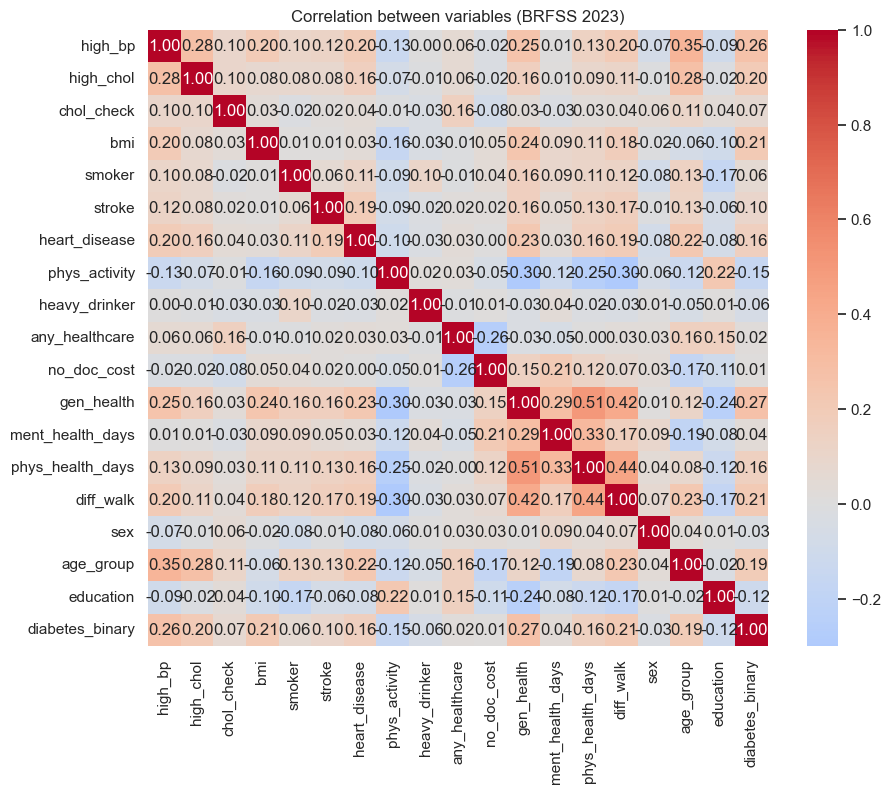

In [14]:
# Correlation between every pair of columns (leave out the survey weight)
corr = df.drop(columns=["weight"]).corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation between variables (BRFSS 2023)")
plt.show()

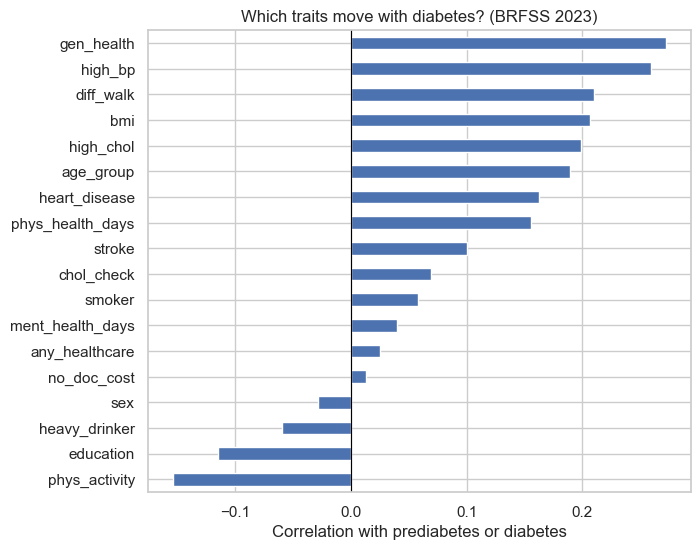

In [15]:
# Only the target's column of the heatmap, sorted, without its own 1.00
target_corr = corr["diabetes_binary"].drop("diabetes_binary").sort_values()

target_corr.plot(kind="barh", figsize=(7, 6))
plt.xlabel("Correlation with prediabetes or diabetes")
plt.title("Which traits move with diabetes? (BRFSS 2023)")
plt.axvline(0, color="black", linewidth=0.8)   # line at zero to separate positive from negative
plt.show()

**Finding:** no single variable has a strong linear link to prediabetes or diabetes. The strongest are self-rated general health (0.27), high blood pressure (0.26), difficulty walking (0.21), BMI (0.21), high cholesterol (0.20) and age (0.19). Physical activity (-0.15) and education (-0.12) are negatively linked. Health-care access variables and sex are close to zero. Age is only 0.19 because its effect levels off at older ages, so it is not a straight line. General health, physical health days and difficulty walking overlap with each other (0.42-0.51), but no pair is high enough to be redundant. No single variable is a strong predictor on its own, so a model that combines them is needed.

## Summary of EDA findings

| Question | Answer |
|---|---|
| Q1. Data and target | 300,760 respondents with complete answers and no missing values. 17.3% have prediabetes or diabetes (82.7% do not), so classes are imbalanced and accuracy alone will mislead in modeling. |
| Q2. Survey weight | One respondent stands for about 241 adults (median). Weighted rate 16.2% vs unweighted 17.3%. |
| Q3. Biggest differences | High blood pressure (71.5% vs 37.5%), high cholesterol (64.0% vs 38.0%) and difficulty walking (32.4% vs 12.2%). On a common scale the largest gaps are general health (0.72), high blood pressure (0.69), difficulty walking (0.56), BMI (0.55), high cholesterol (0.53) and age (0.50); physical activity is the largest in the other direction (-0.41). Heart disease and stroke are 2.6-2.8 times more common but rank lower on the common scale. A weighted check gives the same ordering, with gaps within about 3 points. |
| Q4. BMI | Higher on average (31.6 vs 28.1), with a heavier tail above 35. The groups overlap heavily. |
| Q5. Age | Prevalence rises from about 3% at 18-29 to about 25% at 70-79, then dips to about 22% at 80+. Within each age band, people with high blood pressure, high cholesterol or no physical activity still have clearly higher rates, so those gaps are not just an age effect. || Q6. Sex, education, health | Sex: small gap (about 18.5% vs 16.5%). Education: about 35% down to 13%. General health: about 4.5% (excellent) up to 41% (poor). |
| Q7. Correlations | The strongest are 0.19-0.27, so no single variable is decisive. Physical activity and education are negatively linked. |


## References

- Centers for Disease Control and Prevention (CDC). *Behavioral Risk Factor Surveillance System Survey Data.* Atlanta, Georgia: U.S. Department of Health and Human Services, CDC. https://www.cdc.gov/brfss/annual_data/annual_data.htm
- hesscl. *quackrfss: BRFSS 1990-2024 in Parquet format.* Hugging Face. https://huggingface.co/datasets/hesscl/quackrfss